🎓 **Predicting Student Mental Health Score from Social Media Usage**

**Problem:** We're predicting a student's Mental_Health_Score: (a continuous score from ~3 to ~10) using their social media habits, study time, sleep, physical activity, and stress level. This is a regression problem since the target is a number, not a category.

**Dataset:** *Student_Social_Media_And_Mental_Health_Impact.csv* — 5,000 students, 13 columns covering demographics (Age, Gender, Country), platform usage (Avg_Daily_Usage_Hours, Daily_Unlocks, Most_Used_Platform), lifestyle (Study_Hours, Sleep_Hours_Per_Night, Physical_Activity_Hours), and Stress_Level.

## **1.Import Libraries**

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import warnings
warnings.filterwarnings('ignore')

# **2. Load the Dataset**

In [2]:
df = pd.read_csv('D:/Mental-Health-Predictor/data/Student Social Media And Mental Health Impact.csv')
df.shape

(5000, 13)

In [3]:
df.head()

,Age,Gender,Country,Academic_Level,Most_Used_Platform,Purpose_Of_Use,Avg_Daily_Usage_Hours,Daily_Unlocks,Study_Hours,Physical_Activity_Hours,Sleep_Hours_Per_Night,Stress_Level,Mental_Health_Score
0,21,Male,Other,Undergraduate,Facebook,Networking,4.0,134,4.5,2.2,6.7,Medium,6.8
1,23,Female,Other,Graduate,LinkedIn,Education,1.6,73,7.0,2.4,8.6,Low,7.6
2,22,Male,Canada,Undergraduate,Instagram,Entertainment,4.6,166,4.0,1.8,6.7,Medium,7.0
3,18,Male,Other,High School,Snapchat,Entertainment,7.0,220,1.0,1.7,5.4,Very High,5.3
4,24,Female,Other,Graduate,Facebook,Networking,7.5,237,1.0,1.1,5.0,Very High,4.4


In [4]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 5000 entries, 0 to 4999
Data columns (total 13 columns):
 #   Column                   Non-Null Count  Dtype  
---  ------                   --------------  -----  
 0   Age                      5000 non-null   int64  
 1   Gender                   5000 non-null   object 
 2   Country                  5000 non-null   object 
 3   Academic_Level           5000 non-null   object 
 4   Most_Used_Platform       5000 non-null   object 
 5   Purpose_Of_Use           5000 non-null   object 
 6   Avg_Daily_Usage_Hours    5000 non-null   float64
 7   Daily_Unlocks            5000 non-null   int64  
 8   Study_Hours              5000 non-null   float64
 9   Physical_Activity_Hours  5000 non-null   float64
 10  Sleep_Hours_Per_Night    5000 non-null   float64
 11  Stress_Level             5000 non-null   object 
 12  Mental_Health_Score      5000 non-null   float64
dtypes: float64(5), int64(2), object(6)
memory usage: 507.9+ KB


In [5]:
df.describe()

,Age,Avg_Daily_Usage_Hours,Daily_Unlocks,Study_Hours,Physical_Activity_Hours,Sleep_Hours_Per_Night,Mental_Health_Score
count,5000.00000,5000.000000,5000.000000,5000.000000,5000.000000,5000.000000,5000.000000
mean,20.82180,5.078460,171.452600,3.008420,1.751000,6.634580,6.230980
std,1.73662,1.653913,42.858254,1.637018,0.668398,1.221391,1.278701
min,18.00000,1.000000,62.000000,0.300000,-0.400000,3.600000,3.600000
25%,19.00000,3.800000,140.000000,1.500000,1.300000,5.600000,5.100000
50%,21.00000,5.000000,171.000000,2.800000,1.700000,6.600000,6.100000
75%,22.00000,6.300000,204.000000,4.200000,2.200000,7.500000,7.100000
max,24.00000,8.800000,273.000000,8.300000,4.100000,9.900000,9.400000


📌 **Reading this:** Most columns look reasonable — but look closely at ***Physical_Activity_Hours***: the minimum value is **-0.4.** Negative hours aren't physically possible, so this is a data-entry glitch, not a real value. We'll fix this properly in the Data Cleaning step below instead of ignoring it.

## **4. Exploratory Data Analysis (EDA)**

### **4.1 — Distribution of the target** (*Mental_Health_Score*)

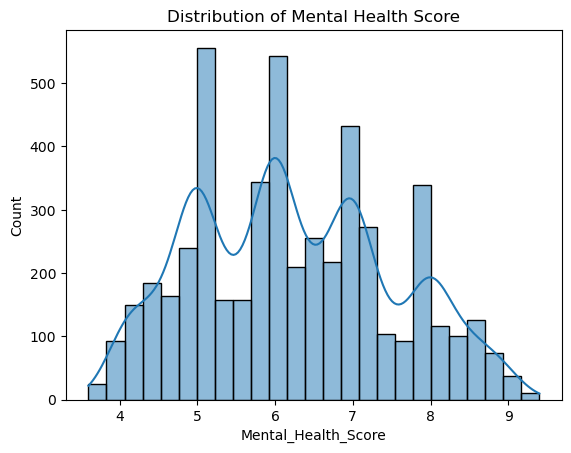

In [6]:
sns.histplot(df['Mental_Health_Score'],kde=True)
plt.title('Distribution of Mental Health Score')
plt.show()

In [7]:
df.columns

Index(['Age', 'Gender', 'Country', 'Academic_Level', 'Most_Used_Platform',
       'Purpose_Of_Use', 'Avg_Daily_Usage_Hours', 'Daily_Unlocks',
       'Study_Hours', 'Physical_Activity_Hours', 'Sleep_Hours_Per_Night',
       'Stress_Level', 'Mental_Health_Score'],
      dtype='object')

### **4.2 — Distribution of the target** (*SEX_Distribution*)

<Axes: xlabel='Gender', ylabel='count'>

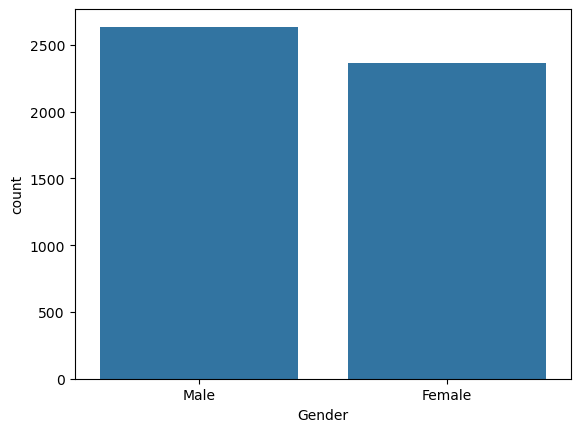

In [8]:
sns.countplot(data=df,x="Gender")


Above plot shows **Gender Distribution** --> which is almost equal.

### **4.3 — Correlation Heatmap**

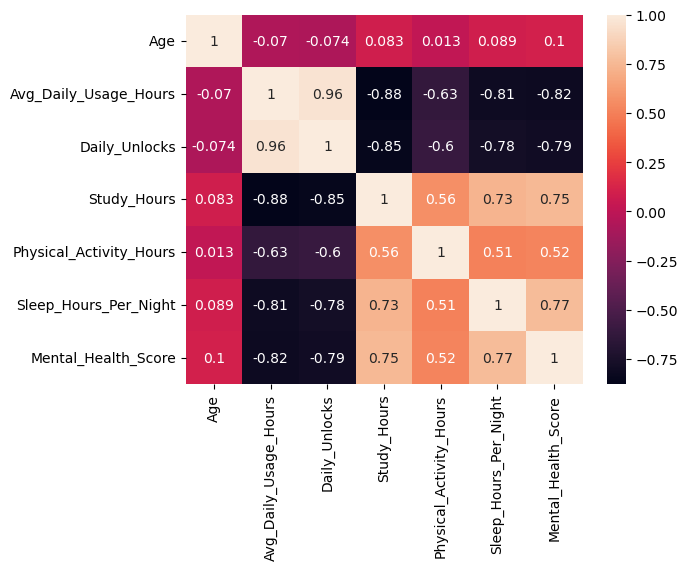

In [9]:
sns.heatmap(df.corr(numeric_only=True),annot=True)
plt.show()

### **4.4 — Stress_Level v/s Mental_Health_Score**

In [10]:
df['Stress_Level'].value_counts()

Stress_Level
Very High    1621
High         1440
Medium       1295
Low           644
Name: count, dtype: int64

In [11]:
df['Stress_Level'].unique()

array(['Medium', 'Low', 'Very High', 'High'], dtype=object)

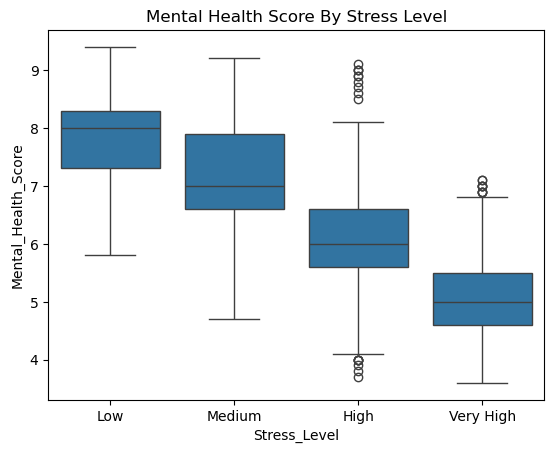

In [12]:
order_list = ['Low','Medium','High','Very High']
sns.boxplot(data=df,x='Stress_Level',y='Mental_Health_Score',order=order_list)
plt.title('Mental Health Score By Stress Level')
plt.show()

As **Stress increases Mental Health decreases**

### **4.5 — Daily Usage Hours v/s Mental Health Score**

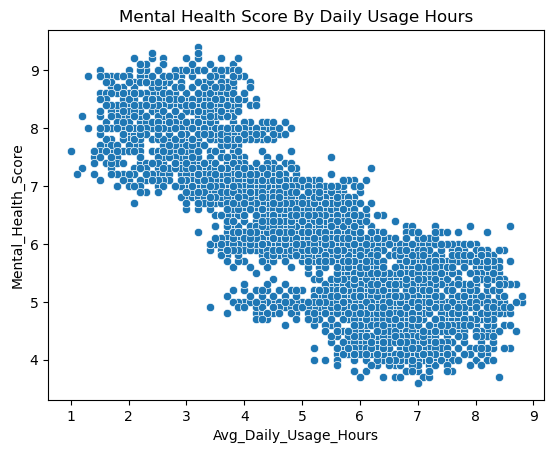

In [13]:
sns.scatterplot(data=df,x='Avg_Daily_Usage_Hours',y='Mental_Health_Score')
plt.title('Mental Health Score By Daily Usage Hours')
plt.show()

* This shows negative correlation between Mental Health and Uses of social media.

### **4.6 — Sleep Hours v/s Mental Health Score**

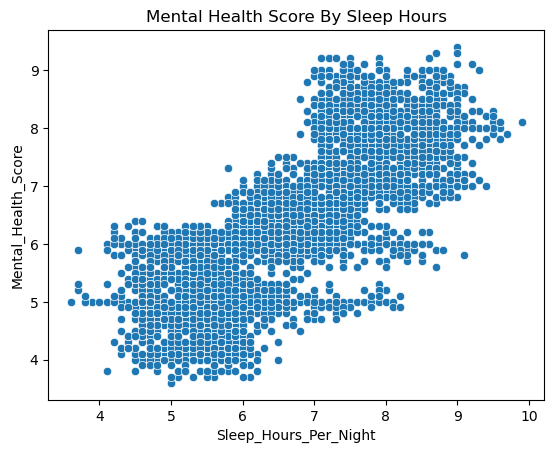

In [14]:
sns.scatterplot(data=df,x='Sleep_Hours_Per_Night',y='Mental_Health_Score')
plt.title('Mental Health Score By Sleep Hours')
plt.show()

**4.7 — Study Hours v/s Mental Health Score**

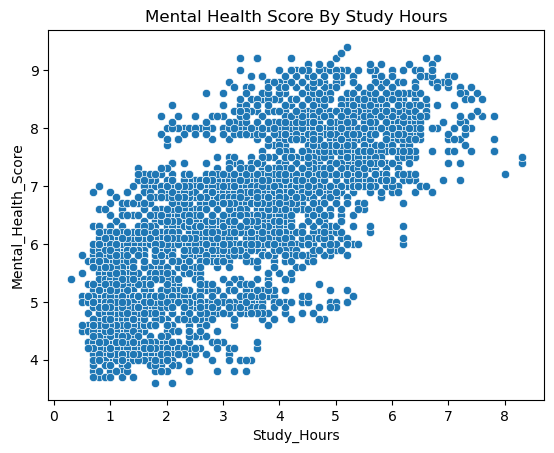

In [15]:
sns.scatterplot(data=df,x='Study_Hours',y='Mental_Health_Score')
plt.title('Mental Health Score By Study Hours')
plt.show()

### **4.8 - Physical_Activity_Hours v/s Mental Health Score**

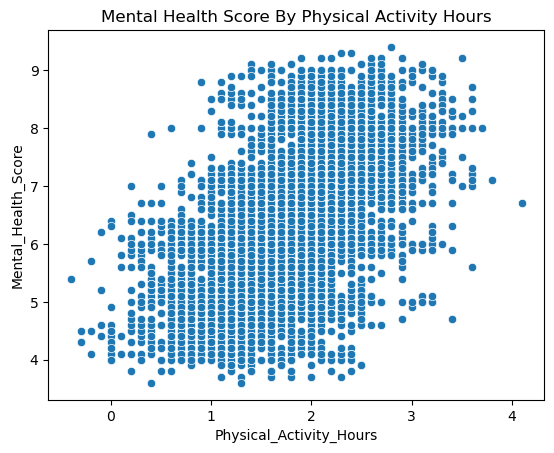

In [16]:
sns.scatterplot(data=df,x='Physical_Activity_Hours',y='Mental_Health_Score')
plt.title('Mental Health Score By Physical Activity Hours')
plt.show()

### **4.9 - Sleep_Hours_Per_Night v/s Mental Health Score**

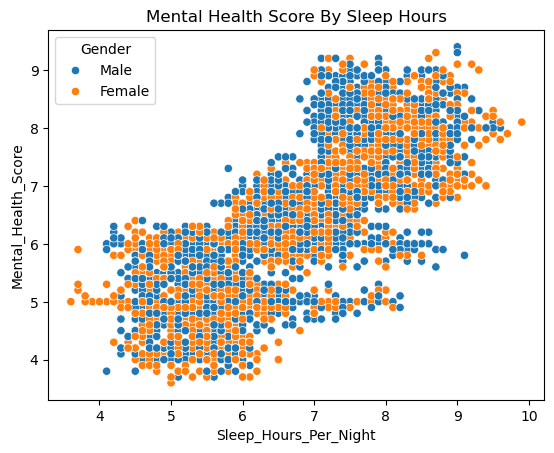

In [17]:
sns.scatterplot(data=df, x="Sleep_Hours_Per_Night", y="Mental_Health_Score", hue="Gender")
plt.title('Mental Health Score By Sleep Hours')
plt.show()

In [18]:
df.columns

Index(['Age', 'Gender', 'Country', 'Academic_Level', 'Most_Used_Platform',
       'Purpose_Of_Use', 'Avg_Daily_Usage_Hours', 'Daily_Unlocks',
       'Study_Hours', 'Physical_Activity_Hours', 'Sleep_Hours_Per_Night',
       'Stress_Level', 'Mental_Health_Score'],
      dtype='object')

### **Most Common Used Platforms:**
 Take a quick look which platforms are used most in our datasets.

In [19]:
df

,Age,Gender,Country,Academic_Level,Most_Used_Platform,Purpose_Of_Use,Avg_Daily_Usage_Hours,Daily_Unlocks,Study_Hours,Physical_Activity_Hours,Sleep_Hours_Per_Night,Stress_Level,Mental_Health_Score
0,21,Male,Other,Undergraduate,Facebook,Networking,4.0,134,4.5,2.2,6.7,Medium,6.8
1,23,Female,Other,Graduate,LinkedIn,Education,1.6,73,7.0,2.4,8.6,Low,7.6
2,22,Male,Canada,Undergraduate,Instagram,Entertainment,4.6,166,4.0,1.8,6.7,Medium,7.0
3,18,Male,Other,High School,Snapchat,Entertainment,7.0,220,1.0,1.7,5.4,Very High,5.3
4,24,Female,Other,Graduate,Facebook,Networking,7.5,237,1.0,1.1,5.0,Very High,4.4
...,...,...,...,...,...,...,...,...,...,...,...,...,...
4995,18,Female,Other,High School,YouTube,Education,1.9,89,6.1,2.2,7.9,Low,7.9
4996,18,Female,Other,High School,YouTube,Education,6.6,216,2.3,1.8,6.0,Very High,4.7
4997,19,Female,India,Undergraduate,LinkedIn,Education,3.8,151,5.4,1.4,7.5,Medium,7.0
4998,18,Male,Other,High School,Instagram,Entertainment,3.8,119,4.0,1.5,6.4,Medium,6.7


In [20]:
df['Most_Used_Platform'].value_counts()

Most_Used_Platform
Instagram    1130
TikTok        918
Facebook      719
LinkedIn      523
YouTube       491
Twitter       462
Snapchat      420
WhatsApp      175
LINE           50
VKontakte      40
KakaoTalk      36
WeChat         36
Name: count, dtype: int64

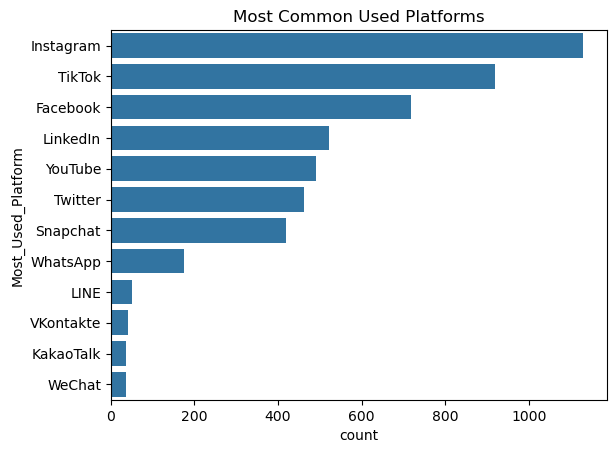

In [21]:
sns.countplot(data=df,y='Most_Used_Platform',order=df['Most_Used_Platform'].value_counts().index)
plt.title('Most Common Used Platforms')
plt.show()

### **Checking Outliers:**

In [22]:
num_features = df.select_dtypes(exclude='object')
Q1 = num_features.quantile(0.25)
Q3 = num_features.quantile(0.75)
IQR = Q3 - Q1

Upper_limit = Q3 + 1.5 * IQR
Lower_limit = Q1 - 1.5 * IQR

outlier = (num_features < Lower_limit) | (num_features > Upper_limit)
print(outlier.sum())

Age                         0
Avg_Daily_Usage_Hours       0
Daily_Unlocks               0
Study_Hours                 2
Physical_Activity_Hours    22
Sleep_Hours_Per_Night       0
Mental_Health_Score         0
dtype: int64


* We can keep the outliers because it is only **0.44% of Original Datasets**

## **5. Data Cleaning:**

In [23]:
# Checking duplicate and null value in data
print('Total duplicate value :',df.duplicated().sum())
print('Checking Null Values:\n',df.isnull().sum())

Total duplicate value : 2
Checking Null Values:
 Age                        0
Gender                     0
Country                    0
Academic_Level             0
Most_Used_Platform         0
Purpose_Of_Use             0
Avg_Daily_Usage_Hours      0
Daily_Unlocks              0
Study_Hours                0
Physical_Activity_Hours    0
Sleep_Hours_Per_Night      0
Stress_Level               0
Mental_Health_Score        0
dtype: int64


In [24]:
# Droping duplicate value
df.drop_duplicates(inplace=True)
print('Total duplicate value :',df.duplicated().sum())

Total duplicate value : 0


In [25]:
df.describe()

,Age,Avg_Daily_Usage_Hours,Daily_Unlocks,Study_Hours,Physical_Activity_Hours,Sleep_Hours_Per_Night,Mental_Health_Score
count,4998.000000,4998.000000,4998.000000,4998.000000,4998.000000,4998.000000,4998.000000
mean,20.822129,5.078491,171.455582,3.008403,1.750760,6.634654,6.231152
std,1.736774,1.654097,42.859829,1.636831,0.668406,1.221561,1.278476
min,18.000000,1.000000,62.000000,0.300000,-0.400000,3.600000,3.600000
25%,19.000000,3.800000,140.000000,1.500000,1.300000,5.600000,5.100000
50%,21.000000,5.000000,171.000000,2.800000,1.700000,6.600000,6.100000
75%,22.000000,6.300000,204.000000,4.200000,2.200000,7.500000,7.100000
max,24.000000,8.800000,273.000000,8.300000,4.100000,9.900000,9.400000


In [26]:
df['Physical_Activity_Hours'] = df['Physical_Activity_Hours'].clip(lower=0)
#df.describe()

📌 **Why clip(lower=0) and not dropping the row:** Cliping caps do not remove the entire rows. It only convert to good format

## **6. Checking For Skewness:**

In [27]:
num_cols = df.select_dtypes(exclude='object')
skew = num_cols.skew()
skew

Age                        0.155008
Avg_Daily_Usage_Hours      0.005575
Daily_Unlocks              0.002309
Study_Hours                0.436125
Physical_Activity_Hours    0.053288
Sleep_Hours_Per_Night      0.123919
Mental_Health_Score        0.207086
dtype: float64

All data values is near to Zero so it is Centralised

## **7. Feature Engineering:**

In [28]:
df

,Age,Gender,Country,Academic_Level,Most_Used_Platform,Purpose_Of_Use,Avg_Daily_Usage_Hours,Daily_Unlocks,Study_Hours,Physical_Activity_Hours,Sleep_Hours_Per_Night,Stress_Level,Mental_Health_Score
0,21,Male,Other,Undergraduate,Facebook,Networking,4.0,134,4.5,2.2,6.7,Medium,6.8
1,23,Female,Other,Graduate,LinkedIn,Education,1.6,73,7.0,2.4,8.6,Low,7.6
2,22,Male,Canada,Undergraduate,Instagram,Entertainment,4.6,166,4.0,1.8,6.7,Medium,7.0
3,18,Male,Other,High School,Snapchat,Entertainment,7.0,220,1.0,1.7,5.4,Very High,5.3
4,24,Female,Other,Graduate,Facebook,Networking,7.5,237,1.0,1.1,5.0,Very High,4.4
...,...,...,...,...,...,...,...,...,...,...,...,...,...
4995,18,Female,Other,High School,YouTube,Education,1.9,89,6.1,2.2,7.9,Low,7.9
4996,18,Female,Other,High School,YouTube,Education,6.6,216,2.3,1.8,6.0,Very High,4.7
4997,19,Female,India,Undergraduate,LinkedIn,Education,3.8,151,5.4,1.4,7.5,Medium,7.0
4998,18,Male,Other,High School,Instagram,Entertainment,3.8,119,4.0,1.5,6.4,Medium,6.7


In [29]:
df['Country'].nunique()

111

**One meaningful feature engineering here:** Groupby **'Country'**
* Country has **111 unique values** in this dataset — **one-hot encoding **that directly would add **110+ mostly-empty columns**, which hurts the model far more than it helps (this is called high cardinality).
* D**ropping Country entirely** throws away real signal — a student's country genuinely correlates with things like internet access, culture, and sleep norms.
* **The fix:** keep the top 10 most frequent countries as their own category, and bucket everything else into "Other". We keep the signal that matters and lose the noise that doesn't.

In [30]:
top_countries = df['Country'].value_counts().index[:10].to_list()

In [31]:
# Generating function for iterating country columns

def group_countries(country):
  if country in top_countries:
    return country
  else:
    return 'Other'

In [32]:
df['Groped_Country'] = df['Country'].apply(group_countries)

In [33]:
df

,Age,Gender,Country,Academic_Level,Most_Used_Platform,Purpose_Of_Use,Avg_Daily_Usage_Hours,Daily_Unlocks,Study_Hours,Physical_Activity_Hours,Sleep_Hours_Per_Night,Stress_Level,Mental_Health_Score,Groped_Country
0,21,Male,Other,Undergraduate,Facebook,Networking,4.0,134,4.5,2.2,6.7,Medium,6.8,Other
1,23,Female,Other,Graduate,LinkedIn,Education,1.6,73,7.0,2.4,8.6,Low,7.6,Other
2,22,Male,Canada,Undergraduate,Instagram,Entertainment,4.6,166,4.0,1.8,6.7,Medium,7.0,Canada
3,18,Male,Other,High School,Snapchat,Entertainment,7.0,220,1.0,1.7,5.4,Very High,5.3,Other
4,24,Female,Other,Graduate,Facebook,Networking,7.5,237,1.0,1.1,5.0,Very High,4.4,Other
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
4995,18,Female,Other,High School,YouTube,Education,1.9,89,6.1,2.2,7.9,Low,7.9,Other
4996,18,Female,Other,High School,YouTube,Education,6.6,216,2.3,1.8,6.0,Very High,4.7,Other
4997,19,Female,India,Undergraduate,LinkedIn,Education,3.8,151,5.4,1.4,7.5,Medium,7.0,India
4998,18,Male,Other,High School,Instagram,Entertainment,3.8,119,4.0,1.5,6.4,Medium,6.7,Other


## **8. Encoding Strategy:**

* **Stress_Level**→ Ordinal Encoding. Its categories have a real, meaningful order: **Low < Medium < High < Very High**. We already saw in EDA (section 4.3) that the score drops step by step as stress increases — encoding it as 0, 1, 2, 3 preserves that order for the model.
* **Gender, Academic_Level, Most_Used_Platform, Purpose_Of_Use, Country_Grouped → One-Hot Encoding.**

## **9. Train_Test_Split:**

In [34]:
from sklearn.model_selection import train_test_split

skwewd_col         = ['Study_Hours']
other_numeric_cols = ["Age", "Avg_Daily_Usage_Hours", "Daily_Unlocks","Physical_Activity_Hours",
                      "Sleep_Hours_Per_Night"]
ordinal_col        = ['Stress_Level']
normal_col         = ["Gender", "Academic_Level", "Most_Used_Platform", "Purpose_Of_Use", "Groped_Country"]


feature_col = skwewd_col + other_numeric_cols + ordinal_col + normal_col
X = df[feature_col]
y = df['Mental_Health_Score']

X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.30, random_state=42)

## **10. Preprocessing using ColumnTransformer**

Our columns need **different treatment:**

* **Study_Hours** (the skewed one) → impute → log1p transform → scale
* The **other numeric columns** → impute → scale (no skew to fix)
S* tress_Level → impute → OrdinalEncoder with an explicit order
* The **nominal columns** → impute → OneHotEncoder

We include a **SimpleImputer** in every branch even though this dataset has zero missing values right now — it's a safety net. Real-world data (and our future API's incoming requests) won't always be this clean, and a pipeline that assumes "no missing values ever" is a pipeline that breaks in production.

**ColumnTransformer** glues all of this into **one object** that applies the right transformation to the right column type in a single .fit() / .transform() call — no manual column-by-column juggling.

In [35]:
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import FunctionTransformer, OrdinalEncoder, OneHotEncoder, StandardScaler
from sklearn.compose import ColumnTransformer

#1. Skewed features
skew_pipeline = Pipeline(steps=[
    ('log_transform', FunctionTransformer(np.log1p)),
    ('scale', StandardScaler())
])

#2. Numeric Features
plain_numeric_pipeline = Pipeline(steps=[
    ('scale', StandardScaler())
])

#3. Ordinal
ordinal_pipeline = Pipeline(steps=[
    ('encode', OrdinalEncoder(categories=[['Low', 'Medium', 'High', 'Very High']]))
])

#4. Nominal Features
nominal_pipeline = Pipeline(steps=[
    ('encode', OneHotEncoder(handle_unknown='ignore'))
])

## Columns Transformer:
preprocessor = ColumnTransformer(transformers=[
    ('Skewed',skew_pipeline,skwewd_col),
    ('Numeric',plain_numeric_pipeline,other_numeric_cols),
    ('Ordinal',ordinal_pipeline,ordinal_col),
    ('Nominal',nominal_pipeline,normal_col)
])

preprocessor

,transformers,"[('Skewed', ...), ('Numeric', ...), ...]"
,remainder,'drop'
,sparse_threshold,0.3
,n_jobs,None
,transformer_weights,None
,verbose,False
,verbose_feature_names_out,True
,force_int_remainder_cols,'deprecated'
,func,<ufunc 'log1p'>
,inverse_func,None
,validate,False


# **11.  Model Building:**

## **11.1 — Baseline: Linear Regression**

In [36]:
from sklearn.linear_model import LinearRegression
from sklearn.metrics import mean_squared_error,mean_absolute_error, r2_score

lr_pipeline = Pipeline(steps=[
    ('preprocessor',preprocessor),
    ('regressor_model', LinearRegression())
])

lr_pipeline.fit(X_train, y_train)
lr_pred = lr_pipeline.predict(X_test)
lr_pred_train = lr_pipeline.predict(X_train)

lr_r2_testing = r2_score(y_test, lr_pred)
lr_r2_training = r2_score(y_train, lr_pred_train)
lr_mae         = mean_absolute_error(y_test, lr_pred)


print("Accuracy of Training:",lr_r2_training)
print("Accuracy of Testing:",lr_r2_testing)
print("MAE:",lr_mae)


Accuracy of Training: 0.7236771199387539
Accuracy of Testing: 0.739794461743302
MAE: 0.5361775634720183


## **11.2 — Random Forest ( default_settings)**

In [37]:
from sklearn.ensemble import RandomForestRegressor

rf_pipeline = Pipeline(steps=[
    ('preprocessor', preprocessor),
    ('rf_model', RandomForestRegressor())
])

rf_pipeline.fit(X_train, y_train)
rf_pred = rf_pipeline.predict(X_test)
rf_pred_train = rf_pipeline.predict(X_train)

rf_r2_testing = r2_score(y_test, rf_pred)
rf_r2_training = r2_score(y_train, rf_pred_train)
rf_mae         = mean_absolute_error(y_test, rf_pred)

print("Accuracy of Training:",rf_r2_training)
print("Accuracy of Testing:",rf_r2_testing)
print("MAE:",rf_mae)

Accuracy of Training: 0.9812207250363487
Accuracy of Testing: 0.8778625041284793
MAE: 0.3462992666666668


## **11.3 — Hyperparameter Tuning the Random Forest**(*using RandomizedSearchCV*)


In [38]:
from sklearn.model_selection import RandomizedSearchCV
from sklearn.ensemble import RandomForestRegressor
from sklearn.pipeline import Pipeline


rf_pipeline = Pipeline(steps=[
    ('preprocessor', preprocessor),
    ('rf_model', RandomForestRegressor())
])


parm_grid = {
    'rf_model__n_estimators': [100, 200, 300, 400, 500],
    'rf_model__max_depth': [5, 10, 20, 30],
    'rf_model__min_samples_split': [2, 5, 10],
    'rf_model__min_samples_leaf': [1, 2, 4]
}

random_search = RandomizedSearchCV(
    estimator=rf_pipeline,
    param_distributions=parm_grid,
    n_iter=15,
    cv=5,
    scoring='r2',
    random_state=42,
    n_jobs=-1
)

random_search.fit(X_train, y_train)

,estimator,Pipeline(step...Regressor())])
,param_distributions,"{'rf_model__max_depth': [5, 10, ...], 'rf_model__min_samples_leaf': [1, 2, ...], 'rf_model__min_samples_split': [2, 5, ...], 'rf_model__n_estimators': [100, 200, ...]}"
,n_iter,15
,scoring,'r2'
,n_jobs,-1
,refit,True
,cv,5
,verbose,0
,pre_dispatch,'2*n_jobs'
,random_state,42
,error_score,nan


In [39]:
random_search.best_params_

{'rf_model__n_estimators': 400,
 'rf_model__min_samples_split': 2,
 'rf_model__min_samples_leaf': 1,
 'rf_model__max_depth': 20}

In [40]:
rf_best_pipeline = random_search.best_estimator_
rf_best_pred = rf_best_pipeline.predict(X_test)

print(f"R2 score for random forest after hyperparameter testing{r2_score(y_test, rf_best_pred)}")
print(f"MAE score for random forest after hyperparameter testing{mean_absolute_error(y_test, rf_best_pred)}")

R2 score for random forest after hyperparameter testing0.8791427116339112
MAE score for random forest after hyperparameter testing0.34562901867120205


# **12. Model Evaluation**

In [48]:
from sklearn.metrics import mean_squared_error

# Calculate RMSE for Linear Regression
lr_rmse = np.sqrt(mean_squared_error(y_test, lr_pred))

# Calculate RMSE for default Random Forest
rf_rmse = np.sqrt(mean_squared_error(y_test, rf_pred))

# Calculate RMSE for tuned Random Forest
rf_tuned_preds          = random_search.best_estimator_.predict(X_test)
rf_tuned_rmse           = np.sqrt(mean_squared_error(y_test, rf_tuned_preds))
rf_tuned_training_preds = random_search.best_estimator_.predict(X_train)
r2_tuned_training       = r2_score(y_train, rf_tuned_training_preds)
rf_tuned_mae            = mean_absolute_error(y_test, rf_tuned_preds)
rf_tuned_r2             = r2_score(y_test, rf_tuned_preds)


# Create a DataFrame to consolidate results
results = pd.DataFrame({
    'Model': ['Linear Regression', 'Random Forest (default)', 'Random Forest (tuned)'],
    'R2': [lr_r2_testing, rf_r2_testing, rf_tuned_r2],
    'Training R2': [lr_r2_training, rf_r2_training, r2_tuned_training],
    'MAE': [lr_mae, rf_mae, rf_tuned_mae],
    'RMSE': [lr_rmse, rf_rmse, rf_tuned_rmse]
})

print(results)

                     Model        R2  Training R2       MAE      RMSE
0        Linear Regression  0.739794     0.723677  0.536178  0.676032
1  Random Forest (default)  0.877863     0.981221  0.346299  0.463163
2    Random Forest (tuned)  0.879143     0.980693  0.345629  0.460729


## **13. Save the Model**

In [52]:
import os
import joblib

# Create models folder outside notebooks
os.makedirs('../models', exist_ok=True)

# Save model
joblib.dump(rf_pipeline, '../models/Mental_Health_model.pkl')

print("Model saved successfully!")

Model saved successfully!
